<a href="https://colab.research.google.com/github/giovanardo/DATA201-labs/blob/main/Copy_of_Week_9_Decision_Trees_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 9 Lab: Your First Decision Trees

**Goals.** By the end of this lab you will be able to:
1. Fit, plot, and read a classification tree and a regression tree
2. Check by hand how a split is scored (Gini impurity)
3. See overfitting happen, then control it with pruning
4. Read feature importances, and know what they can and cannot tell you

**Dataset (two files from ISLP):**
- `Heart.csv`: 303 patients, predict heart disease (`AHD`: Yes/No), a *classification* task
- `Hitters.csv`: baseball players, predict `Salary`, a *regression* task



## 0. Setup

In [ ]:
%pip -q install ISLP

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ISLP import load_data

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

#plt.rcParams['figure.dpi'] = 100

## 1. Load and prepare the Heart data

Each row is a patient. The target `AHD` says whether angiographic heart disease was found. Two columns (`ChestPain`, `Thal`) are text categories. A scikit-learn tree needs numbers, so we turn each category into 0/1 columns (*one-hot encoding*). Note that we do **not** need to scale any features: trees only compare a feature to a threshold, so scale does not matter.

In [ ]:
# Load Heart dataset directly from the textbook website
url = "https://www.statlearning.com/s/Heart.csv"

heart = pd.read_csv(url)

# Remove index column
heart = heart.drop(columns=['Unnamed: 0'], errors='ignore')

print(heart.shape)
heart.head()

(303, 14)


,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal,AHD
0,63,1,typical,145,233,1,2,150,0,2.3,3,0.0,fixed,No
1,67,1,asymptomatic,160,286,0,2,108,1,1.5,2,3.0,normal,Yes
2,67,1,asymptomatic,120,229,0,2,129,1,2.6,2,2.0,reversable,Yes
3,37,1,nonanginal,130,250,0,0,187,0,3.5,3,0.0,normal,No
4,41,0,nontypical,130,204,0,2,172,0,1.4,1,0.0,normal,No


In [ ]:
# Which columns have missing values?
print(heart.isna().sum())

# There are only a few, so we simply drop those rows
heart = heart.dropna()
print('Rows left:', len(heart))

# Turn the target into 1 (disease) / 0 (no disease)
heart['AHD'] = (heart['AHD'] == 'Yes').astype(int)
print(heart['AHD'].value_counts())

Age          0
Sex          0
ChestPain    0
RestBP       0
Chol         0
Fbs          0
RestECG      0
MaxHR        0
ExAng        0
Oldpeak      0
Slope        0
Ca           4
Thal         2
AHD          0
dtype: int64
Rows left: 297
AHD
0    160
1    137
Name: count, dtype: int64


In [ ]:
# One-hot encode the two text columns using pd this time!
X = pd.get_dummies(heart.drop(columns='AHD'), columns=['ChestPain', 'Thal']).astype(int)
y = heart['AHD']

# Hold out 30% of patients for testing. stratify keeps the class mix similar in both parts.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)


print(X_train.shape, X_test.shape)

#you can check your sets (X_train, X_test,...)
X_train.head()

(207, 18) (90, 18)


,Age,Sex,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,ChestPain_asymptomatic,ChestPain_nonanginal,ChestPain_nontypical,ChestPain_typical,Thal_fixed,Thal_normal,Thal_reversable
115,41,1,135,203,0,0,132,0,0,2,0,0,0,1,0,1,0,0
94,63,0,135,252,0,2,172,0,0,1,0,0,1,0,0,0,1,0
186,42,1,120,240,1,0,194,0,0,3,0,0,1,0,0,0,0,1
68,59,1,170,326,0,2,140,1,3,3,0,1,0,0,0,0,0,1
86,47,1,138,257,0,2,156,0,0,1,0,0,1,0,0,0,1,0


## 2. Your first tree

We start with a very small tree (`max_depth=2`: at most two questions on any path) so we can read all of it.

- `DecisionTreeClassifier()` creates a classification tree. The algorithm uses the training data to determine which predictors and cutpoints produce the best splits. By default, scikit-learn uses Gini impurity to select splits.


`plot_tree` draws it. Each box shows:


- the **test** (`feature <= threshold`): *True* goes left, *False* goes right
- `gini`: how mixed the classes are in that node (0 = pure)
- `samples`: training patients that reach the node
- `value`: how many patients of each class `[no disease, disease]`
- `class`: the majority class, which is the prediction if the tree stops here

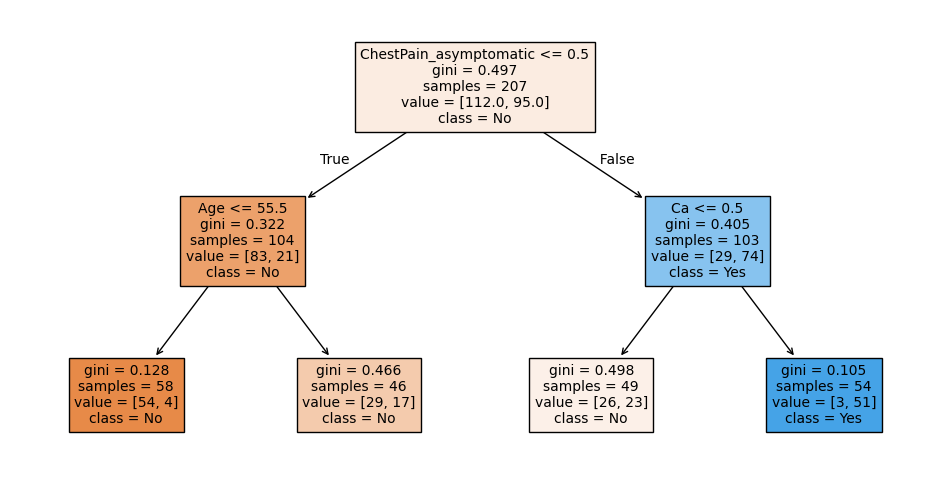

Train accuracy: 0.773
Test accuracy:  0.744


In [ ]:
tree2 = DecisionTreeClassifier(max_depth=2, random_state=0)
tree2.fit(X_train, y_train)

#figure's size
plt.figure(figsize=(12, 6))

plot_tree(tree2,
          feature_names=list(X.columns),
          class_names=['No', 'Yes'], #here "No" is first, because we set it up to be 0. class_names only changes the labels displayed on the tree. It does not change the model's predictions.
          filled=True, #colors nodes based on their predicted class. Stronger colors indicates greater purity
          fontsize=10)
plt.show()

print('Train accuracy:', round(tree2.score(X_train, y_train), 3))
print('Test accuracy: ', round(tree2.score(X_test, y_test), 3))

### Your turn 1: read the tree
Using the plot above, answer in a text cell or a comment:
1. Which feature is tested at the root?
2. Pick any leaf. How many training patients reach it, and what does it predict?
3. Then check yourself: use `predict` and `predict_proba` on the **first test patient**.

In [ ]:
first_patient = X_test.iloc[[0]]

#get the tree's predicted class for first_patient
pred = tree2.predict(first_patient)

#get the predicted class probabilities for first_patient
proba = tree2.predict_proba(first_patient)

print('Prediction:', pred)
print('Probabilities [No, Yes]:', proba)


# Now follow this patient's values down the plotted tree. Do you land in the same leaf?

# We can start from root and follow the patient's predictor values
display(first_patient[['ChestPain_asymptomatic', 'Age','Ca']])

# Or, we can look at the leaves, and compare the patient's probability to them.
#Patient's pr(NO)=0.5306, and the Pr(No) in the leaves (left to right:the probability of No = 93%, 63%, 53%, 6%)




Prediction: [0]
Probabilities [No, Yes]: [[0.53061224 0.46938776]]


,ChestPain_asymptomatic,Age,Ca
245,1,67,0


## 3. How is a split chosen? Check Gini by hand

For a node with class proportions $p_k$, the **Gini index** is $G = \sum_k p_k(1-p_k)$, which equals $1 - \sum_k p_k^2$. It is 0 for a pure node and largest when classes are evenly mixed. The tree tries every feature and cutpoint, and keeps the split whose two child nodes have the lowest **weighted** Gini.

Let us verify this for the root of `tree2`.

In [ ]:
def gini(labels):
    p = labels.value_counts(normalize=True)
    return 1 - (p ** 2).sum()

# Gini of the root node, by hand and from the fitted tree
print('Root Gini (by hand):  ', round(gini(y_train), 4))
print('Root Gini (sklearn):  ', round(tree2.tree_.impurity[0], 4))

Root Gini (by hand):   0.4966
Root Gini (sklearn):   0.4966


1. **Gini is calculated using y (the target variable), not X (the predictors).** It measures how mixed the classes are within a node. The tree uses X to create splits and y to evaluate their impurity.

2. **`gini(y_train)` calculates Gini for the root** because the root contains all training observations. `tree2.tree_.impurity[0]` retrieves the root's Gini directly from the fitted tree, where `[0]` represents the root node.

3. **`normalize=True` converts class counts into proportions.** Instead of returning 112 No and 95 Yes, it returns 0.5411 and 0.4589. These proportions (p) are used to calculate Gini.

### So how does the decision Tree work:

A decision tree starts with all training observations in the root node.

1. It measure how mixed the classes are before splitting.
2. Then it tests different predictors and cutpoints to divide the observations into two groups.
3. Then it measures the combined impurity of the two resulting groups, accounting for their sizes.
4. Selects the predictor and cutpoint that produce the lowest weighted Gini (largest reduction in impurity).
5. Apply the same process to each new node until a stopping condition is reached.

**In the following code, we will examine the first split selected by our tree and calculate how much it reduced Gini impurity.**

In [ ]:
# Get the feature and threshold chosen at the root
feat = X_train.columns[tree2.tree_.feature[0]]
thr = tree2.tree_.threshold[0]

print('Root split:', feat, '<=', thr)

# Divide patients into left and right groups
left = y_train[X_train[feat] <= thr]
right = y_train[X_train[feat] > thr]

# Calculate weighted Gini after the split
weighted_gini = (len(left)*gini(left) + len(right)*gini(right)) / len(y_train)

print('Weighted Gini:', round(weighted_gini, 4))
print('Impurity at the root:',round(gini(y_train), 4))
print('Gini reduction:', round(gini(y_train) - weighted_gini, 4))

Root split: ChestPain_asymptomatic <= 0.5
Weighted Gini: 0.3632
Impurity at the root: 0.4966
Gini reduction: 0.1334


### Try another feature:

Compute the weighted Gini for the test **`Sex <= 0.5`** (female vs. male). Is it better or worse than the split the tree chose?

In [ ]:
left = y_train[X_train['Sex'] <= 0.5]
right = y_train[X_train['Sex'] > 0.5]
w = (len(left) * gini(left) + len(right) * gini(right)) / len(y_train)
print('Weighted Gini for Sex <= 0.5:', round(w, 4))

Weighted Gini for Sex <= 0.5: 0.461


## 4. Watch a tree overfit

If we do not limit the tree, it keeps splitting until every leaf is **pure**. Let us see what that does.

In [ ]:
full = DecisionTreeClassifier(random_state=0).fit(X_train, y_train)
print('Depth:', full.get_depth(), '  Leaves:', full.get_n_leaves())
print('Train accuracy:', round(full.score(X_train, y_train), 3))
print('Test accuracy: ', round(full.score(X_test, y_test), 3))

Depth: 8   Leaves: 32
Train accuracy: 1.0
Test accuracy:  0.789


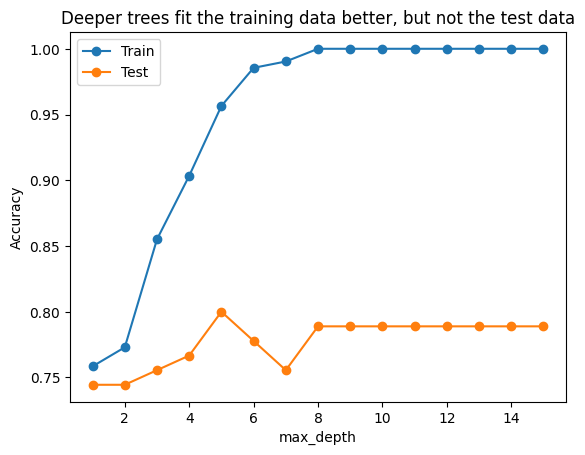

In [ ]:
# Train vs. test accuracy as the tree is allowed to grow deeper
depths = range(1, 16)
train_acc, test_acc = [], []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=0).fit(X_train, y_train)
    train_acc.append(m.score(X_train, y_train))
    test_acc.append(m.score(X_test, y_test))

plt.plot(depths, train_acc, marker='o', label='Train')
plt.plot(depths, test_acc, marker='o', label='Test')
plt.xlabel('max_depth'); plt.ylabel('Accuracy'); plt.legend()
plt.title('Deeper trees fit the training data better, but not the test data')
plt.show()

Training accuracy keeps climbing to 1.0 (the tree has memorized the training patients), while test accuracy stalls or drops. That gap is **overfitting**.  

*Careful:* we looked at the test set to draw this picture, which is fine for learning what overfitting looks like. To actually **choose** settings we must not use the test set. In the next section we use cross-validation on the training data instead.

## 5. Controlling complexity: pruning

**Pre-pruning** stops the tree early with settings such as `max_depth`, `max_leaf_nodes`, or `min_samples_leaf` (every leaf must keep at least that many patients). **Post-pruning** grows a big tree and then cuts it back. In scikit-learn the cost complexity version is the `ccp_alpha` setting.

In [ ]:
# Pre-pruning: require at least 10 training patients in every leaf
pre = DecisionTreeClassifier(min_samples_leaf=10, random_state=0).fit(X_train, y_train)


print('Depth:', pre.get_depth(), '  Leaves:', pre.get_n_leaves())
print('Train accuracy:', round(pre.score(X_train, y_train), 3))
print('Test accuracy: ', round(pre.score(X_test, y_test), 3))

Depth: 4   Leaves: 12
Train accuracy: 0.884
Test accuracy:  0.789


### Your turn: try a different pre-pruning setting

Fit a tree with `max_leaf_nodes=6`. Report its number of leaves, train accuracy, and test accuracy. How does it compare with the full tree from section 4?

In [ ]:
# TODO: fit a DecisionTreeClassifier with max_leaf_nodes=6 (use random_state=0)
tree6 = None

# TODO: print leaves (get_n_leaves()), train accuracy, and test accuracy


Depth: 4 Leaves: 6
Train accuracy: 0.845
Test accuracy:  0.789


### Choosing settings with cross-validation
`GridSearchCV` tries every combination of settings, scores each with 5-fold cross-validation **on the training data only**, and keeps the best.

In [ ]:
grid = GridSearchCV(
    DecisionTreeClassifier(random_state=0),
    param_grid={'max_depth': [1, 2, 3, 4, 5, 6, 8, 10],
                'min_samples_leaf': [1, 5, 10, 20]},
    cv=5)

grid.fit(X_train, y_train)

print('Best settings:', grid.best_params_)
print('Best CV accuracy:', round(grid.best_score_, 3))
print('Test accuracy of best model:', round(grid.score(X_test, y_test), 3))

Best settings: {'max_depth': 3, 'min_samples_leaf': 10}
Best CV accuracy: 0.783
Test accuracy of best model: 0.789


### Post-pruning with `ccp_alpha`
Cost complexity pruning scores a subtree as *error + α × (number of leaves)*. With α = 0 we keep the full tree; larger α gives smaller trees. scikit-learn can list the useful values of α for us, and we pick one by cross-validation.

This code demonstrates post-pruning: growing a large decision tree and then removing branches that do not contribute enough to its predictive performance.

The goal is to find a tree that is not unnecessarily complex and performs well on new data.

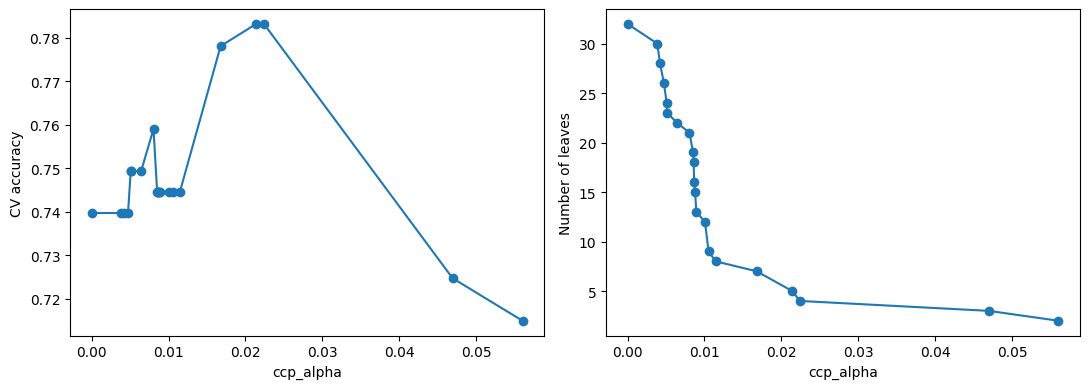

Best alpha: 0.0214   Leaves: 5
Test accuracy of pruned tree: 0.778


In [ ]:
path = DecisionTreeClassifier(random_state=0).cost_complexity_pruning_path(X_train, y_train) #cost_complexity_pruning_path() finds the effective alpha values at which branches can be pruned.
alphas = path.ccp_alphas[:-1]          # the last alpha prunes everything down to the root

cv_acc, n_leaves = [], []

#For every alpha value, the code does two things.
#1-Evaluate predictive performance
#2-Measure tree complexity (how many leaves)
for a in alphas:
    m = DecisionTreeClassifier(ccp_alpha=a, random_state=0)
    cv_acc.append(cross_val_score(m, X_train, y_train, cv=5).mean())
    n_leaves.append(m.fit(X_train, y_train).get_n_leaves())

#graph
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(alphas, cv_acc, marker='o'); ax[0].set_xlabel('ccp_alpha'); ax[0].set_ylabel('CV accuracy')
ax[1].plot(alphas, n_leaves, marker='o'); ax[1].set_xlabel('ccp_alpha'); ax[1].set_ylabel('Number of leaves')
plt.tight_layout(); plt.show()

#best alpha
best_alpha = alphas[int(np.argmax(cv_acc))]

#Finally, train the final pruned tree
pruned = DecisionTreeClassifier(ccp_alpha=best_alpha, random_state=0).fit(X_train, y_train)

print('Best alpha:', round(best_alpha, 4), '  Leaves:', pruned.get_n_leaves())
print('Test accuracy of pruned tree:', round(pruned.score(X_test, y_test), 3))

## 6. Interpreting a tree

**Reading the rules.** `export_text` prints the tree as nested if/else rules, which is handy for explaining a model to someone who has not seen the plot.

In [ ]:
print(export_text(pruned, feature_names=list(X.columns)))

|--- ChestPain_asymptomatic <= 0.50
|   |--- Age <= 55.50
|   |   |--- class: 0
|   |--- Age >  55.50
|   |   |--- class: 0
|--- ChestPain_asymptomatic >  0.50
|   |--- Ca <= 0.50
|   |   |--- Thal_reversable <= 0.50
|   |   |   |--- class: 0
|   |   |--- Thal_reversable >  0.50
|   |   |   |--- class: 1
|   |--- Ca >  0.50
|   |   |--- class: 1



**Feature importance** scores each feature from 0 (never used) to 1, and all of them sum to 1.

Remember from lecture: importance has **no direction** (it does not say whether high values mean disease), and a low score does not mean a feature is useless, since another feature may carry the same information.

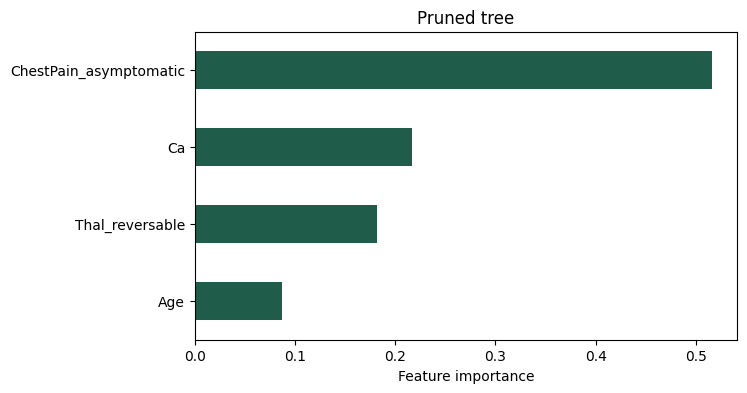

In [ ]:
imp = pd.Series(pruned.feature_importances_, index=X.columns).sort_values()

imp[imp > 0].plot(kind='barh', figsize=(7, 4), color='#1F5C4A')
plt.xlabel('Feature importance'); plt.title('Pruned tree'); plt.show()

**Trees are unstable.** They have high variance: small changes in training data can produce different trees and different predictions.

Below we refit a depth-3 tree on five different random splits of the same data and look at what the root asks.

In [ ]:
for seed in range(5):

    # Create a different train/test split each time
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.3, random_state=seed, stratify=y)

    # Train a decision tree
    tree7 = DecisionTreeClassifier(max_depth=3, random_state=0)
    tree7.fit(X_train, y_train)

    # Identify the root split
    root = X.columns[tree7.tree_.feature[0]]
    threshold = tree7.tree_.threshold[0]

    # Display results
    print(f'Split {seed}: Root = {root}, Threshold = {threshold:.2f}, '
          f'Test accuracy = {tree7.score(X_test, y_test):.3f}')

Split 0: Root = Thal_normal, Threshold = 0.50, Test accuracy = 0.744
Split 1: Root = Thal_normal, Threshold = 0.50, Test accuracy = 0.733
Split 2: Root = ChestPain_asymptomatic, Threshold = 0.50, Test accuracy = 0.800
Split 3: Root = Thal_normal, Threshold = 0.50, Test accuracy = 0.767
Split 4: Root = ChestPain_asymptomatic, Threshold = 0.50, Test accuracy = 0.833


Decision trees have high variance: Different training samples can produce different tree structures, even when the algorithm and hyperparameters remain the same. This instability is one of the main weaknesses of single decision trees.

As mentioned in the lecture: Random Forests address this problem by combining predictions from many decision trees rather than relying on a single tree.

## 7. A regression tree: baseball salaries

Now the response is a number, so each leaf predicts the **mean** of the training responses in it, and splits are chosen to minimize RSS (instead of Gini). We predict $\log(\text{Salary})$ because Salary is skewed. Salary is recorded in thousands of dollars.

In [ ]:
hit = load_data('Hitters')

# Remove index column
hit = hit.drop(columns=['Unnamed: 0'], errors='ignore')
print('Rows before dropping missing Salary:', len(hit))


hit = hit.dropna()
hit['logSalary'] = np.log(hit['Salary'])
print('Rows after:', len(hit))

hit[['Years', 'Hits', 'Salary', 'logSalary']].head()

Rows before dropping missing Salary: 322
Rows after: 263


,Years,Hits,Salary,logSalary
1,14,81,475.0,6.163315
2,3,130,480.0,6.173786
3,11,141,500.0,6.214608
4,2,87,91.5,4.516339
5,11,169,750.0,6.620073


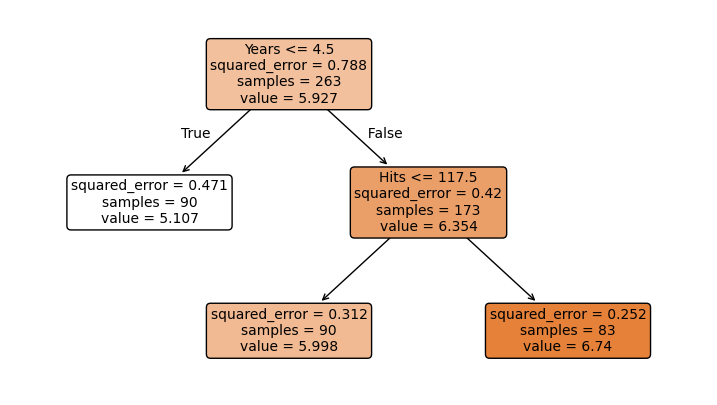

In [ ]:
# Reproduce the textbook tree: only Years and Hits, three leaves
reg3 = DecisionTreeRegressor(max_leaf_nodes=3, random_state=0)
reg3.fit(hit[['Years', 'Hits']], hit['logSalary'])

plt.figure(figsize=(9, 5))
plot_tree(reg3, feature_names=['Years', 'Hits'], filled=True, rounded=True, fontsize=10)
plt.show()


In classification trees, colors represent predicted classes and their purity. In regression trees, colors represent the predicted numerical values. Darker color= higher predicted log salary

In [ ]:
# Create three hypothetical players
players = pd.DataFrame({'Years': [3, 10, 10], 'Hits': [50, 80, 150]})

# Predict log salary using the regression tree
players['Predicted Log Salary'] = reg3.predict(players)

# Convert log salary to dollars
players['Predicted Salary ($)'] = (np.exp(players['Predicted Log Salary']) * 1000).round(0)

players

,Years,Hits,Predicted Log Salary,Predicted Salary ($)
0,3,50,5.106790,165139.0
1,10,80,5.998380,402776.0
2,10,150,6.739687,845296.0


Now use all the predictors (one-hot encoding the three text columns). We choose `max_depth` by cross-validation on the training data, using RMSE on the log scale, and compare against linear regression.

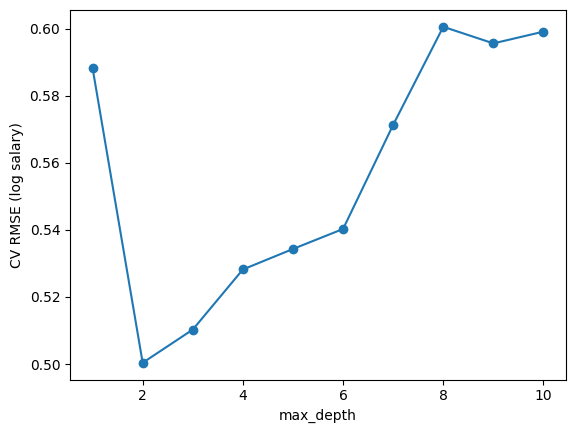

Best max_depth: 2
Test RMSE, tree:              0.665
Test RMSE, linear regression: 0.678


In [ ]:
X = pd.get_dummies(hit.drop(columns=['Salary', 'logSalary']), drop_first=True).astype(float)
y = hit['logSalary']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

depths = range(1, 11)
cv_rmse = []
for d in depths:
    m = DecisionTreeRegressor(max_depth=d, random_state=0)
    scores = cross_val_score(m, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error')
    cv_rmse.append(-scores.mean())

plt.plot(depths, cv_rmse, marker='o')
plt.xlabel('max_depth'); plt.ylabel('CV RMSE (log salary)'); plt.show()

best_d = list(depths)[int(np.argmin(cv_rmse))]
best_tree = DecisionTreeRegressor(max_depth=best_d, random_state=0).fit(X_train, y_train)
lin = LinearRegression().fit(X_train, y_train)

def rmse(model): return np.sqrt(mean_squared_error(y_test, model.predict(X_test)))
print('Best max_depth:', best_d)
print('Test RMSE, tree:             ', round(rmse(best_tree), 3))
print('Test RMSE, linear regression:', round(rmse(lin), 3))

The graph shows how tree depth affects the accuracy of salary predictions.

At depth 1, the tree is too simple and may be underfitting.

At **depth 2, the cross-validation RMSE is lowest (0.50)**, indicating the best predictive performance. As the tree grows deeper, RMSE generally increases, suggesting that the tree is overfitting the training data and performing worse on unseen observations. Therefore,

**depth 2 is the best choice based on cross-validation**, demonstrating that a more complex tree does not necessarily produce better predictions.

### Trees cannot extrapolate
A regression tree only ever outputs the mean of some training leaf. Let us see what that means when we ask about a player with far more experience than anyone in the data.

In [ ]:
one = hit[['Years']]
#Train two models using Years only
tree1 = DecisionTreeRegressor(max_depth=3, random_state=0).fit(one, hit['logSalary'])
lin1 = LinearRegression().fit(one, hit['logSalary'])

#Check the maximum experience in the dataset
print('Largest Years in the data:', hit['Years'].max())

#Predict salaries for different experience levels
grid_years = pd.DataFrame({'Years': [5, 15, 25, 40, 60]})


print(pd.DataFrame({'Years': grid_years['Years'],
                    'Tree': tree1.predict(grid_years).round(2),
                    'Linear': lin1.predict(grid_years).round(2)}))

Largest Years in the data: 24
   Years  Tree  Linear
0      5  6.11    5.70
1     15  6.28    6.69
2     25  6.28    7.69
3     40  6.28    9.19
4     60  6.28   11.18


The maximum experience in the dataset is 24 years. For players with 25, 40, or 60 years of experience, the regression tree predicts the **same** log salary (6.28) because they all fall into the same final leaf.

In contrast, linear regression continues increasing its predictions as experience increases, extending (extrapolating) the trend learned from the data.

Neither is right here, but notice the different behavior.


## 8. Wrap-up questions

Answer in your own words in a text cell.

1. What does a leaf predict in a classification tree? In a regression tree?
2. Why did the full tree reach 100% training accuracy but do worse on the test set?
3. Give two ways to limit tree complexity. Which one did cross-validation help you tune?
4. Why do we not need to scale features before fitting a tree?
5. A teammate says "`Age` has importance 0, so it is irrelevant to heart disease." What is wrong with that claim? (answer in terms of reducing impurity)
6. Name one strength and one weakness of a single decision tree that you saw in this lab.

### For the homework use the below code

In [ ]:
from ISLP import load_data
carseats = load_data('Carseats')

carseats.head()

,Sales,CompPrice,Income,Advertising,Population,Price,ShelveLoc,Age,Education,Urban,US
0,9.50,138,73,11,276,120,Bad,42,17,Yes,Yes
1,11.22,111,48,16,260,83,Good,65,10,Yes,Yes
2,10.06,113,35,10,269,80,Medium,59,12,Yes,Yes
3,7.40,117,100,4,466,97,Medium,55,14,Yes,Yes
4,4.15,141,64,3,340,128,Bad,38,13,Yes,No


In [ ]:
# Convert Sales into categories: High = 1, Low = 0
carseats['HighSales'] = (carseats['Sales'] > 8).astype(int)
carseats = carseats.drop(columns=['Sales'])

# Check the number of stores in each category
print(carseats['HighSales'].value_counts())

HighSales
0    236
1    164
Name: count, dtype: int64
